In [1]:
import numpy as np
import matplotlib.pylab as plt
import xarray as xr ## unnecessary for Figure 10
import os
import pickle

#import sys
import xgcm
from xmitgcm import open_mdsdataset
import MITgcmutils ## unnecessary for Figure 10

In [2]:
pwd = os.getcwd()
print(pwd)

/home/groups/earlew/nbcoffey/idealized_channel_demo/analysis/shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun


In [3]:
group_scratch_dir = '/oak/stanford/groups/earlew/nbcoffey'#'/scratch/groups/earlew/nbcoffey'

In [5]:
# specify experiment directories
exp_home_dir = os.path.join(group_scratch_dir, 'research/modeling/MITgcm/experiments')

# exp_names = ['shelf_demo'] #<--- update if necessary
# exp_names_alias = ['shelf_demo']
# exp_names = ['shelf_drake500_ramp2ridge500_nocontinent_H3km_v02_noaabw_fixZR_80Nz_branch01_layers/', 
#              'shelf_drake500_ramp2ridge500_nocontinent_H3km_v02_noaabw_fixZR_80Nz_branch01_incr_wsc_SG_layers/']
# exp_names_alias = ['Old Control', '$\\tau_E$ N-shift']#, 'simplex ZR']

exp_names = ['shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_year200_layers', 
             'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_incr_wsc_SG_subpolarONLYfixMag_year200_layers',
             'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_25pct_wgb_y1375km_year200_layers',
             'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_contract_fixMag_year200_layers']

# exp_names_alias = ['Ridge+Bumps', '$\\tau_E$ N-shift', '$1.25\,\\tau_W^{\\mathrm{Max}}$', '$\\tau_W$ S-shift']
exp_names_alias = ['Control', '$\\tau_E$ N-shift', '$1.25\,\\tau_W^{\\mathrm{Max}}$', '$\\tau_W$ S-shift']

In [6]:
# load output ## technically not necessary for Fig 10
run_config = {}
output = {}

prefix_list = ['THETA_inst', 'VVEL_inst', 'UVEL_inst']#, 'ETAN_inst']
# got an issue with Etan at one of these timesteps. Don't love that.
# Could not find the expected file prefixes ['THETA_inst', 'VVEL_inst', 'UVEL_inst', 'ETAN_inst'] 
# at iternum 4.84303e+06. (Instead found ['UVEL_inst', 'THETA_inst', 'VVEL_inst'])

#iters = [80449, 160898, 241347, 321796, 402245, 482694, 563143, 643592, 724041, 804490, 884939]
iters = 'all'
for i,exp_name in enumerate(exp_names):
    print(i)
    
    results_dir = os.path.join(exp_home_dir, exp_name, 'results')

    # load run_config file (saved at the end of the run_config notebook)
    input_dir = os.path.join(exp_home_dir, exp_name, 'input')
    params_fpath = os.path.join(input_dir, 'params.p')
    with open(params_fpath, 'rb') as f:
        run_config[exp_name] = pickle.load(f)
        
    # load model output as an xarray dataset, which is essentially a netcdf file
    output_ds = open_mdsdataset(data_dir=results_dir, prefix=prefix_list, 
                          geometry='cartesian', iters=iters)
    
    output[exp_name] = output_ds

0
1


In [7]:
output[exp_name]

<xarray.Dataset>
Dimensions:              (XC: 400, XG: 400, YC: 250, YG: 250, Z: 80, Zl: 80, Zp1: 81, Zu: 80, layer_1TH_bounds: 44, layer_1TH_center: 43, layer_1TH_interface: 42, time: 730)
Coordinates:
  * XC                   (XC) >f4 5e+03 1.5e+04 2.5e+04 ... 3.985e+06 3.995e+06
  * YC                   (YC) >f4 5e+03 1.5e+04 2.5e+04 ... 2.485e+06 2.495e+06
  * XG                   (XG) >f4 0.0 1e+04 2e+04 ... 3.97e+06 3.98e+06 3.99e+06
  * YG                   (YG) >f4 0.0 1e+04 2e+04 ... 2.47e+06 2.48e+06 2.49e+06
  * Z                    (Z) >f4 -3.42 -10.26 -17.11 ... -2.898e+03 -2.966e+03
  * Zp1                  (Zp1) >f4 0.0 -6.841 -13.69 ... -2.932e+03 -3e+03
  * Zu                   (Zu) >f4 -6.841 -13.69 -20.54 ... -2.932e+03 -3e+03
  * Zl                   (Zl) >f4 0.0 -6.841 -13.69 ... -2.864e+03 -2.932e+03
    rA                   (YC, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dxG                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dyG                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    Depth                (YC, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAz                  (YG, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dxC                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dyC                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAw                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAs                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    drC                  (Zp1) >f4 dask.array<chunksize=(81,), meta=np.ndarray>
    drF                  (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
    PHrefC               (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
    PHrefF               (Zp1) >f4 dask.array<chunksize=(81,), meta=np.ndarray>
    hFacC                (Z, YC, XC) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    hFacW                (Z, YC, XG) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    hFacS                (Z, YG, XC) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskC                (Z, YC, XC) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskW                (Z, YC, XG) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskS                (Z, YG, XC) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    rhoRef               (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
  * layer_1TH_bounds     (layer_1TH_bounds) >f4 -1.0 -0.9 -0.8 ... 11.0 12.0
  * layer_1TH_center     (layer_1TH_center) float32 -0.95 -0.85 ... 10.5 11.5
  * layer_1TH_interface  (layer_1TH_interface) >f4 -0.9 -0.8 -0.7 ... 10.0 11.0
    iter                 (time) int64 dask.array<chunksize=(1,), meta=np.ndarray>
  * time                 (time) timedelta64[ns] 74 days 11:45:18 ... 78 days ...
Data variables:
    VVEL                 (time, Z, YG, XC) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    THETA                (time, Z, YC, XC) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    UVEL                 (time, Z, YC, XG) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>

In [6]:
# load output that has been averaged over the entire run.
# it is set in the model setup - the averaging window is 50 years since Earle set it to be that. You can go back in and change this, but I am not sure how to change your averaging window in an ad hoc manner.

run_config_avgs = {}
avgs = {}

prefix_list = ['UVEL', 'VVEL', 'THETA',  'VVELTH', 'UVELTH', 
                    'ETAN', 'UVELSQ', 'VVELSQ', 'WVEL'] ## only a subset used for Figure 10

# prefix_list = ['UVEL', 'VVEL', 'THETA',  'VVELTH', 'UVELTH']

#iters = [80449, 160898, 241347, 321796, 402245, 482694, 563143, 643592, 724041, 804490, 884939]
iters = 'all'
for i,exp_name in enumerate(exp_names):
    print(f"Processing experiment {i}: {exp_name}")
    
    results_dir = os.path.join(exp_home_dir, exp_name, 'results')

    # load run_config file (saved at the end of the run_config notebook)
    input_dir = os.path.join(exp_home_dir, exp_name, 'input')
    params_fpath = os.path.join(input_dir, 'params.p')
    with open(params_fpath, 'rb') as f:
        run_config_avgs[exp_name] = pickle.load(f)
        
    # load model output as an xarray dataset, which is essentially a netcdf file
    avgs_ds = open_mdsdataset(data_dir=results_dir, prefix=prefix_list, 
                          geometry='cartesian', iters=iters)
    avgs[exp_name] = avgs_ds
    


Processing experiment 0: shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_year200_layers
Processing experiment 1: shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_incr_wsc_SG_subpolarONLYfixMag_year200_layers
Processing experiment 2: shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_25pct_wgb_y1375km_year200_layers
Processing experiment 3: shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_contract_fixMag_year200_layers


In [7]:
avgs[exp_name]

<xarray.Dataset>
Dimensions:              (XC: 400, XG: 400, YC: 250, YG: 250, Z: 80, Zl: 80, Zp1: 81, Zu: 80, layer_1TH_bounds: 44, layer_1TH_center: 43, layer_1TH_interface: 42, time: 31)
Coordinates:
  * XC                   (XC) >f4 5e+03 1.5e+04 2.5e+04 ... 3.985e+06 3.995e+06
  * YC                   (YC) >f4 5e+03 1.5e+04 2.5e+04 ... 2.485e+06 2.495e+06
  * XG                   (XG) >f4 0.0 1e+04 2e+04 ... 3.97e+06 3.98e+06 3.99e+06
  * YG                   (YG) >f4 0.0 1e+04 2e+04 ... 2.47e+06 2.48e+06 2.49e+06
  * Z                    (Z) >f4 -3.534 -10.61 -17.68 ... -2.994e+03 -3.065e+03
  * Zp1                  (Zp1) >f4 0.0 -7.069 -14.14 ... -3.03e+03 -3.1e+03
  * Zu                   (Zu) >f4 -7.069 -14.14 -21.22 ... -3.03e+03 -3.1e+03
  * Zl                   (Zl) >f4 0.0 -7.069 -14.14 ... -2.959e+03 -3.03e+03
    rA                   (YC, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dxG                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dyG                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    Depth                (YC, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAz                  (YG, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dxC                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dyC                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAw                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAs                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    drC                  (Zp1) >f4 dask.array<chunksize=(81,), meta=np.ndarray>
    drF                  (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
    PHrefC               (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
    PHrefF               (Zp1) >f4 dask.array<chunksize=(81,), meta=np.ndarray>
    hFacC                (Z, YC, XC) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    hFacW                (Z, YC, XG) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    hFacS                (Z, YG, XC) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskC                (Z, YC, XC) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskW                (Z, YC, XG) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskS                (Z, YG, XC) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    rhoRef               (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
  * layer_1TH_bounds     (layer_1TH_bounds) >f4 -1.0 -0.9 -0.8 ... 11.0 12.0
  * layer_1TH_center     (layer_1TH_center) float32 -0.95 -0.85 ... 10.5 11.5
  * layer_1TH_interface  (layer_1TH_interface) >f4 -0.9 -0.8 -0.7 ... 10.0 11.0
    iter                 (time) int64 dask.array<chunksize=(1,), meta=np.ndarray>
  * time                 (time) timedelta64[ns] 74 days 13:34:52 ... 85 days ...
Data variables:
    ETAN                 (time, YC, XC) float32 dask.array<chunksize=(1, 250, 400), meta=np.ndarray>
    WVEL                 (time, Zl, YC, XC) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    UVELTH               (time, Z, YC, XG) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    VVEL                 (time, Z, YG, XC) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    UVEL                 (time, Z, YC, XG) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    THETA                (time, Z, YC, XC) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    VVELSQ               (time, Z, YG, XC) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    VVELTH               (time, Z, YG, XC) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    UVELSQ               (time, Z, YC, XG) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>

In [8]:
# create time array using file names

secsInDays = 3600*24
secsInMons = secsInDays*30
secsInYears = secsInDays*365

# time_yrs_dict = {}

for i,exp_name in enumerate(exp_names):
    
    results_dir = os.path.join(exp_home_dir, exp_names[i], 'results')

    
    results_fnames = os.listdir(results_dir)
#     theta_inst_fnames = [fname for fname in results_fnames 
#                          if (fname.startswith('THETA_inst') and fname.endswith('.data'))]


#     # get time stamp info from filenames
#     iters = np.array([int(fname.split('.')[1]) for fname in theta_inst_fnames])
#     iters.sort()
#     #print(iters)

#     mitgcm_params = run_config[exp_name]['mitgcm_params']['data']
#     deltaT = mitgcm_params[2]['deltaT']
#     #print(deltaT)
#     time_secs = iters*deltaT

#     output[exp_name].attrs['time'] = time_secs
    
    # avg ones now
    
    UVELTH_fnames = [fname for fname in results_fnames 
                         if (fname.startswith('UVELTH.') and fname.endswith('.data'))]


    # get time stamp info from filenames
    iters = np.array([int(fname.split('.')[1]) for fname in UVELTH_fnames])
    iters.sort()
    
    mitgcm_params = run_config_avgs[exp_name]['mitgcm_params']['data']
    deltaT = mitgcm_params[2]['deltaT']
    #print(deltaT)
    time_secs_avgs = iters*deltaT

    avgs[exp_name].attrs['time'] = time_secs_avgs
    

In [9]:
# print("Snapshot vars:", time_secs.max()/secsInYears)
print("Time-avg vars:", time_secs_avgs.max()/secsInYears)

Time-avg vars: 229.9999941019787


Computing EKE fields for both experiments...
  Computed EKE for shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_year200_layers
  Computed EKE for shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_incr_wsc_SG_subpolarONLYfixMag_year200_layers
Creating EKE difference plot...


/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:125: UserWarning: linewidths is ignored by contourf


Saved: v1_noNbound_Control_vs_$\tau_E$_N-shift_EKE_diff.pdf


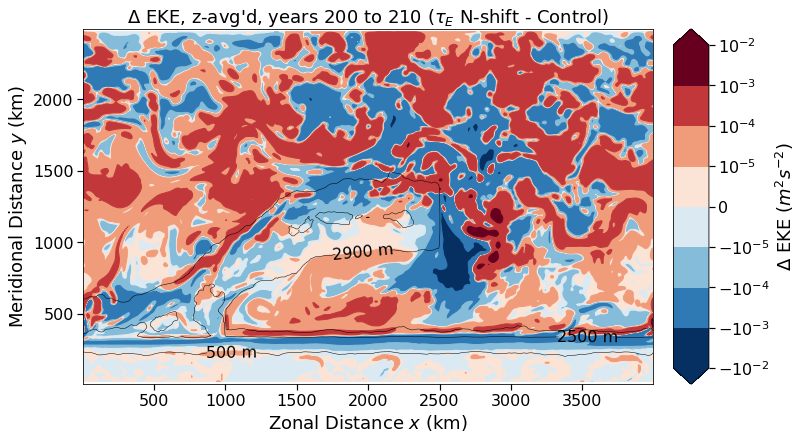

In [11]:
# ============================================================
# USER CONFIGURATION - CHANGE THESE VALUES
# ============================================================
control_idx = 0  # Index of control experiment in exp_names
comparison_idx = 1  # Index of experiment to compare (1, 2, or 3)
# ============================================================

import os
from xgcm import Grid
from matplotlib.colors import BoundaryNorm
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# --- Setup & Formatting Parameters ---
fz = 18  # Global font size
tavgvars = True

if tavgvars:
    tidxequil = 1
    tidx = tidxequil + 9
else:
    tidx = 1

linthresh = 1e-5
dep_lvls = [500, 2500, 2900]

# Select only control and one comparison experiment
selected_exps = [exp_names[control_idx], exp_names[comparison_idx]]
selected_aliases = [exp_names_alias[control_idx], exp_names_alias[comparison_idx]]

# --- Compute EKE for both experiments ---
print("Computing EKE fields for both experiments...")
EKE_data = {}

for exp_name in selected_exps:
    if tavgvars:
        ds = avgs[exp_name]
    else:
        ds = output[exp_name]
        
    grid = Grid(ds, coords={"X": {"center": "XC", "left": "XG"},
                            "Y": {"center": "YC", "left": "YG"}},
                periodic=["X"])  
    
    # 1. Get vertical spacing
    dz = ds['drF']
    
    # 2. Calculate local water column depth at U and V points
    depth_U = (dz * ds['hFacW']).sum(dim='Z')
    depth_V = (dz * ds['hFacS']).sum(dim='Z')
    
    # --- Calculate MKE ---
    # Average over time first
    u_time_mean = avgs[exp_name]['UVEL'][tidxequil:tidx, :, :, :].mean(dim='time') 
    v_time_mean = avgs[exp_name]['VVEL'][tidxequil:tidx, :, :, :].mean(dim='time') 
    
    # Thickness-weighted depth average
    U = (u_time_mean * dz * ds['hFacW']).sum(dim='Z') / depth_U.where(depth_U > 0)
    V = (v_time_mean * dz * ds['hFacS']).sum(dim='Z') / depth_V.where(depth_V > 0)
    
    U_center = grid.interp(U, axis="X", boundary='extend')
    V_center = grid.interp(V, axis="Y", boundary='extend')
    MKE = 0.5 * (U_center**2 + V_center**2)
    
    # --- Calculate Time-averaged KE ---
    usq_time_mean = avgs[exp_name]['UVELSQ'][tidxequil:tidx, :, :, :].mean(dim='time') 
    vsq_time_mean = avgs[exp_name]['VVELSQ'][tidxequil:tidx, :, :, :].mean(dim='time') 
    
    # Thickness-weighted depth average
    USQ = (usq_time_mean * dz * ds['hFacW']).sum(dim='Z') / depth_U.where(depth_U > 0)
    VSQ = (vsq_time_mean * dz * ds['hFacS']).sum(dim='Z') / depth_V.where(depth_V > 0)
    
    USQ_center = grid.interp(USQ, axis="X", boundary='extend')
    VSQ_center = grid.interp(VSQ, axis="Y", boundary='extend')
    KE = 0.5 * (USQ_center + VSQ_center)
    
    # --- Calculate EKE ---
    EKE = KE - MKE
    
    # Free memory
    del U, V, USQ, VSQ, U_center, V_center, USQ_center, VSQ_center
    del u_time_mean, v_time_mean, usq_time_mean, vsq_time_mean  
    
    # Store for plotting
    EKE_data[exp_name] = {'EKE': EKE, 'ds': ds}
    print(f"  Computed EKE for {exp_name}")

# --- Create the difference plot ---
print("Creating EKE difference plot...")

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

# Get data
ds = EKE_data[selected_exps[0]]['ds']
EKE_control = EKE_data[selected_exps[0]]['EKE']
EKE_comparison = EKE_data[selected_exps[1]]['EKE']

x = ds['XC'] / 1e3
y = ds['YC'] / 1e3

# Calculate difference
EKE_diff = EKE_comparison - EKE_control
EKE_diff = EKE_diff.where(EKE_diff != 0)

# Find max absolute value
vmax = np.nanmax(np.abs(EKE_diff.values))

# Create discrete boundaries at powers of 10 (including 1e-2)
max_exp = int(np.floor(np.log10(vmax)))
if max_exp < -2:  # Ensure we include at least 1e-2
    max_exp = -2
min_exp = int(np.floor(np.log10(linthresh)))

# Create boundaries: negative powers, zero, positive powers
neg_bounds = [-10.0**i for i in range(max_exp, min_exp-1, -1)]
pos_bounds = [10.0**i for i in range(min_exp, max_exp+1)]
clvls = neg_bounds + [0] + pos_bounds

# Use BoundaryNorm for discrete bins
norm = BoundaryNorm(clvls, ncolors=256, clip=True)

# Contour plot with rasterization
im = ax.contourf(x, y, EKE_diff, clvls, norm=norm, cmap='RdBu_r', 
                 extend='both', antialiased=True, linewidths=0)
for col in im.collections:
    col.set_edgecolor('face')
    col.set_rasterized(True)

# # Bathymetry Contours
# CS = ax.contour(x, y, ds.Depth, dep_lvls, colors='k', linewidths=0.5)
# ax.clabel(CS, inline=True, fontsize=fz-2, fmt='%d m')
# Add bathymetry contours (excluding the northern boundary)
depth_for_contour = np.copy(ds.Depth)
depth_for_contour[-1, :] = np.nan

CS = plt.contour(x, y, depth_for_contour, dep_lvls, colors='k', linewidths=0.5)
plt.clabel(CS, inline=True, fontsize=fz-2, fmt='%d m')

# Axis Labels
ax.set_ylabel("Meridional Distance $y$ (km)", fontsize=fz)
ax.set_xlabel("Zonal Distance $x$ (km)", fontsize=fz)

# Title
if tavgvars:
    tstmp1 = ds.attrs['time'][tidxequil]/secsInYears
    tstmp2 = ds.attrs['time'][tidx]/secsInYears
    ax.set_title("$\Delta$ EKE, z-avg'd, years $%.0f$ to $%.0f$ (%s - %s)" 
                 %(tstmp1-1, tstmp2, selected_aliases[1], selected_aliases[0]), 
                 fontsize=fz)
else:
    tstmp = ds.attrs['time'][tidx]/secsInYears
    ax.set_title("$\Delta$ EKE, snapshot $t=%.2f$ years (%s - %s)" 
                 %(tstmp, selected_aliases[1], selected_aliases[0]), 
                 fontsize=fz)

# Aspect Ratio and Ticks
ax.set_aspect('equal', adjustable='box')
int_fmt = mticker.FormatStrFormatter('%.0f')
ax.xaxis.set_major_formatter(int_fmt)
ax.yaxis.set_major_formatter(int_fmt)
ax.tick_params(axis='both', which='major', labelsize=fz-2, length=6, width=1.2)

# Colorbar
cb = fig.colorbar(im, ax=ax)
cb.ax.tick_params(axis='y', which='major', labelsize=fz-2, length=6, width=1.2)
cb.set_label('$\Delta$ EKE ($m^2 s^{-2}$)', fontsize=fz)

# Generate ticks for the colorbar
exponents = np.arange(min_exp, max_exp + 1)
pos_ticks = [10.0**exp for exp in exponents]
neg_ticks = [-1 * tick for tick in pos_ticks[::-1]]
all_ticks = neg_ticks + [0] + pos_ticks
cb.set_ticks(all_ticks)
cb.set_ticklabels([f"$-10^{{{int(np.log10(abs(t)))}}}$" if t < 0 
                   else ("0" if t == 0 else f"$10^{{{int(np.log10(t))}}}$") 
                   for t in all_ticks])

# Save the figure
filename = f"v1_noNbound_{selected_aliases[0].replace(' ', '_')}_vs_{selected_aliases[1].replace(' ', '_')}_EKE_diff.pdf"
fig.savefig(filename, dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
print(f"Saved: {filename}")

plt.show()